# 02_logit — ① 비정규화 로지스틱 (logit 담당 P2)
공통 명세 v1의 2~4를 ①에 적용합니다. 실제 Dev(`data/dev_*.parquet`)만 읽고 가짜 데이터는 쓰지 않습니다.

**실행 방법: `런타임 → 모두 실행`만 누르면 됩니다.**
- **Colab**: 첫 칸이 `colab_setup.py`를 받아 실행합니다(Drive 마운트 → 레포 clone/pull → `raw/`·`data/`·`outputs/`·`report/`를 팀 Drive 공유폴더에 연결).
  처음 한 번 Drive 웹에서 공유받은 `LendingClub` 폴더를 '내 드라이브'에 바로가기 추가해야 합니다(편집자 권한). 결과는 Drive에 바로 저장됩니다.
- **내 컴퓨터(Jupyter)**: `lendingclub/notebooks/` 안에서 열면 그대로 돕니다.
- **첫 칸 출력 첫 줄의 config 해시가 core 담당이 공지한 값과 같은지** 눈으로 확인하세요.
- 본 실행 설정입니다: 0절 `B_RUN = B`(100). 시험으로 빨리 돌릴 때만 `B_RUN = 3`으로 바꾸세요. 실제 Dev 4초/회차(666,195행) 기준, 새 Dev(1,109,665행)는 B = 100에 약 10~15분.

정해지지 않은 것은 코드에 `TODO(질문)`으로 남겼습니다.

In [1]:
# ---- Colab 준비 (Colab이 아니면 아무것도 안 함): Drive 연결·레포 받기·notebooks/로 이동. 01_prep과 같은 방식 ----
import os, sys, glob, shutil
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !curl -sL https://raw.githubusercontent.com/Walnutbrown/kdt14th-lendingclub/main/colab_setup.py -o /content/colab_setup.py
    %run -i /content/colab_setup.py
    for p in ("../data/dev_X_raw.parquet", "../data/dev_meta.parquet"):
        assert os.path.exists(p), f"{p} 없음 → core 담당의 새 parquet이 Drive LendingClub/.ipynb/lendingclub/data/에 올라왔는지 확인"
    print("준비 완료. 작업 폴더:", os.getcwd())

In [2]:
SKIP_LIB_TESTS = True
%run -i ./00_config.ipynb
%run -i ./lib_prep.ipynb
%run -i ./lib_engine.ipynb

[config 2026-11-26] 해시 a01f81ea67d1 | STAGE=dev | 미결 3개 (B_TEST, DELTA, XGB_PARAMS), 임시값으로 실행 중
[lib_prep] 해시 e07ddd6943c5


In [3]:
import json, warnings, hashlib, subprocess, time
from fnmatch import fnmatch
from pathlib import Path
import numpy as np, pandas as pd, joblib
from scipy.stats import spearmanr
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

# 앞 칸에서 불러왔어야 하는 것들. 없으면 추측하지 않고 멈춘다.
for name in ("SEED", "B", "MIN_RATE", "SR_MODE", "LOGIT_PARAMS"):
    assert name in globals(), "00_config에 %s가 없음" % name
for name in ("make_preprocessor", "load_categories", "check_columns"):
    assert name in globals(), "lib_prep에 %s가 없음" % name
for name in ("make_oob_splits", "sr_curve", "pick_cutoff", "aggregate_bootstrap", "stack_curves", "fig_a", "fig_b",
             "fit_on", "assert_fit_on"):
    assert name in globals(), "lib_engine에 %s가 없음" % name
assert "rate_eff" in sr_curve(np.array([.1, .2, .3]), np.array([0., 1., 2.]), [0.5]).columns, "예전 lib_engine입니다. v1로 바꾸세요"
print("불러오기 OK")

불러오기 OK


## 0. 설정
값은 00_config에서만 읽습니다(공통 명세 6). 이 노트북에서 정하는 것은 이번 실행의 회차 수 `B_RUN` 하나입니다.

In [4]:
B_RUN = B          # 본 실행 (00_config의 B = 100). 시험 실행만 할 때는 3으로 바꿀 것

ROOT = Path(globals().get("ROOT", ".."))                       # 00_config가 정함 (find_root)
DATA_DIR = Path(globals().get("DATA_DIR", ROOT / "data"))
CONTRACT_DIR = Path(globals().get("CONTRACT_DIR", ROOT / "contract"))
OUT = Path(globals().get("OUT_DIR", ROOT / "outputs")) / "logit"
FIG = Path(globals().get("REPORT_DIR", ROOT / "report")) / "figures"
for d in (OUT, OUT / "models_b", FIG):
    d.mkdir(parents=True, exist_ok=True)

assert SR_MODE in ("with_treasury", "approved_only"), SR_MODE
REF_MODE = "approved_only" if SR_MODE == "with_treasury" else "with_treasury"   # 참고 그림용
print("SEED=%s  B(config)=%s  B_RUN=%s  MIN_RATE=%s  SR_MODE=%s  LOGIT_PARAMS=%s" % (SEED, B, B_RUN, MIN_RATE, SR_MODE, LOGIT_PARAMS))

SEED=42  B(config)=100  B_RUN=3  MIN_RATE=0.05  SR_MODE=with_treasury  LOGIT_PARAMS={'C': inf, 'max_iter': 2000}


## 1. 데이터
`data/dev_X_raw.parquet`(입력 37개, 전처리 전)와 `data/dev_meta.parquet`(y, excess_ret 등)만 읽습니다. 행 순서를 바꾸지 않습니다.

In [5]:
X = pd.read_parquet(DATA_DIR / "dev_X_raw.parquet")
meta = pd.read_parquet(DATA_DIR / "dev_meta.parquet")
assert len(X) == len(meta), "X와 meta의 행 수가 다름"
if (DATA_DIR / "SYNTHETIC_DATA.txt").exists():         # 00_run_p2가 만든 합성 데이터면 표시
    MOCK = True
    print("⚠️ 합성 데이터로 실행 중 (data/SYNTHETIC_DATA.txt). 숫자는 의미 없음. 결과를 팀에 공유하지 마세요")
N_EXPECT = globals().get("EXPECT", {}).get("n_dev")          # 00_config의 01_prep 검증값 (train_new.csv: 1,109,665)
if N_EXPECT is None:
    print("경고: 00_config에 EXPECT['n_dev']가 없음. Dev 행 수 %d를 core 담당 공지와 비교하세요" % len(X))
elif len(X) != N_EXPECT:
    print("경고: Dev 행 수가 %s가 아님 (%d). 01_prep 결과·parquet 버전을 확인하세요" % (f"{N_EXPECT:,}", len(X)))

if "FORBIDDEN_COLS" in globals():
    bad = [c for c in X.columns if any(fnmatch(c, f) for f in FORBIDDEN_COLS)]
    assert not bad, "금지 칼럼이 X에 있음: %s" % bad

y = meta["y"].to_numpy().astype(int)
excess = meta["excess_ret"].to_numpy(dtype=float)
assert np.isfinite(excess).all(), "excess_ret에 결측/무한값이 있음"

with open(CONTRACT_DIR / "signs.json", encoding="utf-8") as f:
    signs = json.load(f)
assert isinstance(signs, dict) and all(v in (-1, 0, 1) for v in signs.values()), \
    "signs.json 형식이 {변수: -1/0/1}이 아님. TODO(질문): 형식 확인"
print("Dev", X.shape, "부도율 %.4f" % y.mean(), "| 부호표 %d개" % len(signs))

Dev (666195, 37) 부도율 0.1626 | 부호표 49개


## 2. 전처리: `make_preprocessor("logit", load_categories())`
연속형만 StandardScaler, 출력 49열. **매 회차 Train_b(중복 포함 그대로)에서만 fit**하고, fit 직후 `check_columns`로 열 계약을 확인합니다.
fit은 `lib_engine.fit_on`으로 하고, 어디서 fit했는지 지문(인덱스 해시)이 남아 Train_b가 아닌 데이터로 fit하면 `assert_fit_on`이 실패합니다.

In [6]:
CATS = load_categories()

def fit_prep(Xraw, train_idx):
    """전처리는 Train_b에서만 fit (lib_engine.fit_on이 fit 위치 지문을 남김). fit 직후 열 계약 확인."""
    prep = fit_on(make_preprocessor("logit", CATS), Xraw, train_idx)
    check_columns(prep, "logit")
    return prep

def tf(prep, Xraw):
    """transform 결과를 열 이름이 붙은 DataFrame으로 (희소행렬이면 밀집으로)."""
    Z = prep.transform(Xraw)
    if hasattr(Z, "toarray"):
        Z = Z.toarray()
    return pd.DataFrame(np.asarray(Z, dtype=float), columns=list(prep.get_feature_names_out()), index=Xraw.index)

## 3. 부트스트랩 B_RUN회 (①)
`LogisticRegression(**LOGIT_PARAMS)` (C=np.inf, max_iter=2000), `random_state=SEED`. 튜닝할 하이퍼파라미터는 없습니다.
회차마다 주 SR_MODE 곡선과 참고 모드 곡선을 둘 다 계산하고, 승인율 1.00에서의 두 모드 SR을 진단 파일에 남깁니다.
계약 파일(`bootstrap_results.csv`, `bootstrap_curves.csv`)의 열은 명세 7 그대로이고, 진단은 별도 파일에 저장합니다.

In [7]:
def fit_logit(Xt, yt):
    """반환: (model, converged). ConvergenceWarning은 플래그로 남기고 다른 경고는 그대로 띄운다."""
    params = {**LOGIT_PARAMS, "random_state": SEED}
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        m = LogisticRegression(**params).fit(Xt, yt)
    converged = True
    for w in caught:
        if issubclass(w.category, ConvergenceWarning):
            converged = False
        else:
            warnings.warn_explicit(w.message, w.category, w.filename, w.lineno)
    return m, converged

def sr_at_full(p, r, mode):
    return float(sr_curve(p, r, [1.0], mode)["sr"].iloc[0])

splits = make_oob_splits(n_samples=len(X), n_bootstrap=B_RUN, seed=SEED)
results, curves, curves_ref, diag = [], [], [], []
for b, (tr, oob) in enumerate(splits):
    t0 = time.time()
    prep = fit_prep(X, tr)
    assert_fit_on(prep, tr)
    m, conv = fit_logit(tf(prep, X.iloc[tr]), y[tr])
    p = m.predict_proba(tf(prep, X.iloc[oob]))[:, 1]
    c = sr_curve(p, excess[oob], RATES, SR_MODE)
    c_ref = sr_curve(p, excess[oob], RATES, REF_MODE)
    a, tau, sr = pick_cutoff(c, MIN_RATE)
    results.append(dict(b=b, a_star=a, tau_star=tau, sr_max=sr,
                        auc=roc_auc_score(y[oob], p), brier=brier_score_loss(y[oob], p)))
    diag.append(dict(b=b, converged=conv, max_abs_beta=float(np.abs(m.coef_).max()), n_oob=len(oob),
                     sr_full_with_treasury=sr_at_full(p, excess[oob], "with_treasury"),
                     sr_full_approved_only=sr_at_full(p, excess[oob], "approved_only")))
    curves.append(c); curves_ref.append(c_ref)
    joblib.dump((prep, m), OUT / "models_b" / ("model_b%03d.joblib" % b))
    print("b=%d  a*=%.2f  SR*=%.4f  AUC=%.4f  수렴=%s  (%.0f초)" % (b, a, sr, results[-1]["auc"], conv, time.time() - t0))

res_df, summ = aggregate_bootstrap(results)
curves_df = stack_curves(curves)                     # 계약 열 (b, rate, sr, tau)
curves_ref_df = stack_curves(curves_ref)
curves_diag_df = stack_curves(curves, extra=True)[["b", "rate", "rate_eff"]]
diag_df = pd.DataFrame(diag)
n_noconv = int((~diag_df["converged"]).sum())
if n_noconv:
    print("경고: %d/%d 회차가 수렴하지 않음 (완전분리 의심). diag의 max_abs_beta 확인" % (n_noconv, B_RUN))
if summ.get("n_failed", 0):
    print("경고: %d 회차에서 유효한 SR이 없어 a*를 못 구함" % summ["n_failed"])
print(res_df.round(4)); print(summ)

b=0  a*=0.47  SR*=0.1729  AUC=0.6883  수렴=True  (4초)
b=1  a*=0.46  SR*=0.1716  AUC=0.6877  수렴=True  (4초)
b=2  a*=0.48  SR*=0.1747  AUC=0.6883  수렴=True  (4초)
   b  a_star  tau_star  sr_max     auc   brier
0  0    0.47    0.1366  0.1729  0.6883  0.1276
1  1    0.46    0.1347  0.1716  0.6877  0.1280
2  2    0.48    0.1395  0.1747  0.6883  0.1276
{'a_star': 0.47, 'a_star_cv': 0.021276595744680812, 'tau_star_cv': 0.017774253230919985, 'sr_max_mean': 0.17306782450226074, 'B': 3, 'n_failed': 0, 'more_stable': 'tau'}


## 4. 최종 모형 (Dev 100% 재학습)과 저장
최종 모형은 같은 설정으로 Dev 전체에 다시 학습합니다. 커트라인은 τ가 아니라 승인율 a*로 옮깁니다.
주 분석에서는 ②의 a*를 ①②③에 공통 적용하므로, 여기의 a*는 ① 자기 a*(강건성 iv용)입니다.

In [8]:
all_idx = np.arange(len(X))
final_prep = fit_prep(X, all_idx)
Xt_full = tf(final_prep, X)
final_m, final_conv = fit_logit(Xt_full, y)
if not final_conv:
    print("경고: 최종 모형이 수렴하지 않음 (완전분리 의심)")

res_df.to_csv(OUT / "bootstrap_results.csv", index=False)
curves_df.to_csv(OUT / "bootstrap_curves.csv", index=False)
curves_ref_df.to_csv(OUT / ("bootstrap_curves_%s.csv" % REF_MODE), index=False)
curves_diag_df.to_csv(OUT / "bootstrap_curves_diag.csv", index=False)
diag_df.to_csv(OUT / "bootstrap_diag.csv", index=False)
joblib.dump((final_prep, final_m), OUT / "final_model.joblib")

def git_commit_of(relpath):
    try:
        out = subprocess.run(["git", "log", "-1", "--format=%H", "--", relpath], cwd=ROOT,
                             capture_output=True, text=True, check=True).stdout.strip()
        return out or None
    except Exception:
        return None

def jsonable(v):
    if isinstance(v, (float, np.floating)) and not np.isfinite(v):
        return str(v)                 # C=np.inf -> "inf"
    return v.item() if isinstance(v, np.generic) else v

signs_commit = git_commit_of("contract/signs.json")
if signs_commit is None:
    print("경고: contract/signs.json의 커밋 해시를 못 찾음 (커밋 전이거나 git 저장소 아님)")
summary = dict(
    a_star=summ["a_star"], a_star_cv=summ["a_star_cv"], tau_star_cv=summ["tau_star_cv"],
    more_stable=summ.get("more_stable"), sr_max_mean=summ["sr_max_mean"], n_failed=summ.get("n_failed", 0),
    B=B_RUN, B_config=B, seed=SEED, sr_mode=SR_MODE, min_rate=MIN_RATE,
    hyperparameters={k: jsonable(v) for k, v in LOGIT_PARAMS.items()},
    columns=list(final_prep.get_feature_names_out()),
    signs_commit=signs_commit,
    config_hash=config_fingerprint() if "config_fingerprint" in globals() else None,
    lib_prep_hash=globals().get("LIB_PREP_HASH"),
    n_not_converged=n_noconv, final_converged=final_conv,
    meta=run_meta() if "run_meta" in globals() else None)   # 00_config의 공통 메타 (설정·미결 목록·패키지 버전)
with open(OUT / "summary.json", "w", encoding="utf-8") as f:
    json.dump({k: jsonable(v) for k, v in summary.items()}, f, ensure_ascii=False, indent=1, default=str)
print(json.dumps({k: summary[k] for k in ("a_star", "a_star_cv", "tau_star_cv", "more_stable", "B")}, ensure_ascii=False))

경고: contract/signs.json의 커밋 해시를 못 찾음 (커밋 전이거나 git 저장소 아님)
{"a_star": 0.47, "a_star_cv": 0.021276595744680812, "tau_star_cv": 0.017774253230919985, "more_stable": "tau", "B": 3}


## 5. 부호 점검 (점검 1·3)
- 점검 1: 분위 구간(10분위)별 부도율과 Spearman 부호. 값 종류가 10개 이하인 변수(0/1, 건수 등)는 값별로 묶습니다(`구간방식` 열에 표시).
  결측과 `MIN_GROUP`건 미만인 구간은 뺍니다.
- 점검 3: ①의 β 부호.
- 둘 다 `contract/signs.json`과 대조합니다. **불일치는 실패가 아니라 보고 대상**입니다. 비단조가 나와도 부호를 뒤집지 않고 0으로 내리는 것만 제안합니다.
- 결과 `sign_check.csv`는 core 담당의 1차 구간표(변수 절)에 ①의 β 부호를 더해 넘기는 자료입니다.

In [9]:
MIN_GROUP = 30

def bin_rates(v, yy, q=10):
    s = pd.DataFrame({"v": v.to_numpy(), "y": yy}).dropna(subset=["v"])
    by_value = s["v"].nunique() <= q
    key = s["v"] if by_value else pd.qcut(s["v"].rank(method="first"), q, labels=False)
    g = s.groupby(key)["y"].agg(["mean", "size"])
    return g.loc[g["size"] >= MIN_GROUP, "mean"], ("값별" if by_value else "10분위")

RAW_COLS = sorted(X.columns, key=len, reverse=True)      # 긴 이름부터 맞춰 봄 (fico_range_low vs fico 같은 경우)

def source_of(col):
    """전처리 후 열 이름 → 원천 변수. 결측 지시(_na, missingindicator_)와 원핫 더미(변수_범주)를 원천으로 합친다."""
    s = col.split("__", 1)[-1]
    if s.startswith("missingindicator_"):
        s = s[len("missingindicator_"):]
    if s.endswith("_na"):
        s = s[:-3]
    for c in RAW_COLS:
        if s == c or s.startswith(c + "_"):
            return c
    return s

beta = pd.Series(final_m.coef_[0], index=Xt_full.columns)
rows = []
for col, s in signs.items():
    if col not in X.columns:
        continue        # signs.json은 전처리 후 열 기준이라 원핫 더미·결측 지시(_na)도 들어 있음 → 원천 변수만 점검
    if not pd.api.types.is_numeric_dtype(X[col]):
        rows.append(dict(변수=col, 부호표=s, 비고="범주형: 구간 점검 생략")); continue
    rate, how = bin_rates(X[col], y)
    rho = spearmanr(rate.index, rate.values)[0] if len(rate) >= 2 and rate.nunique() > 1 else np.nan
    bcol = [c for c in beta.index if c.split("__")[-1] == col]
    bsign = int(np.sign(beta[bcol[0]])) if bcol else np.nan
    rows.append(dict(변수=col, 부호표=s, 구간방식=how, 구간수=len(rate), 구간별_Spearman=round(rho, 2),
                     구간별_부호=int(np.sign(rho)) if abs(rho) > 0.5 else 0,
                     β=round(float(beta[bcol[0]]), 4) if bcol else np.nan, β부호=bsign,
                     β일치=(s == 0) or (s == bsign), 구간일치=(s == 0) or (s == (int(np.sign(rho)) if abs(rho) > 0.5 else 0))))
sign_tbl = pd.DataFrame(rows)
sign_tbl.to_csv(OUT / "sign_check.csv", index=False, encoding="utf-8-sig")
print(sign_tbl.to_string())
nz = sign_tbl[sign_tbl["부호표"] != 0]
print("\n부호표 ±1 변수 %d개 중 β 불일치 %d개, 구간 불일치 %d개 (보고 대상)"
      % (len(nz), int((~nz["β일치"].fillna(True).astype(bool)).sum()), int((~nz["구간일치"].fillna(True).astype(bool)).sum())))

                                변수  부호표  구간방식  구간수  구간별_Spearman  구간별_부호       β  β부호   β일치   구간일치
0                   fico_range_low   -1  10분위   10         -1.00      -1 -0.2247   -1  True   True
1                  credit_hist_len   -1  10분위   10         -1.00      -1 -0.0062   -1  True   True
2                      delinq_2yrs    1  10분위   10          0.32       0  0.0896    1  True  False
3                   inq_last_6mths    1    값별    7          1.00       1  0.0735    1  True   True
4                          pub_rec    1  10분위   10          0.53       1  0.0138    1  True   True
5                         open_acc    0  10분위   10          0.96       1  0.0026    1  True   True
6                        total_acc    0  10분위   10         -0.79      -1 -0.1398   -1  True   True
7                   log_annual_inc   -1  10분위   10         -1.00      -1 -0.1413   -1  True   True
8                       revol_util    1  10분위   10          1.00       1  0.0472    1  True   True
9         

## 6. VIF (최종 모형 설계행렬의 상관행렬 역행렬 대각)
분산 0인 열은 빼고 계산합니다. 원핫 전 범주처럼 완전 공선성이면 의사역행렬을 쓰고 경고합니다.

In [10]:
Xd = Xt_full.loc[:, Xt_full.std() > 1e-12]
dropped = [c for c in Xt_full.columns if c not in Xd.columns]
if dropped:
    print("분산 0이라 VIF에서 뺀 열:", dropped)
# 원핫 더미가 범주 전부 들어 있으면(행마다 합이 1) 완전 공선성이라 VIF가 무한대가 됨 → 변수마다 기준 범주 1개를 빼고 계산
ref_dropped = []
for src, cols in Xd.columns.groupby(Xd.columns.map(source_of)).items():
    cols = list(cols)
    if len(cols) > 1 and np.allclose(Xd[cols].sum(axis=1), 1.0):
        ref_dropped.append(cols[0])
if ref_dropped:
    print("원핫 기준 범주로 VIF에서 뺀 열:", ref_dropped)
Xd = Xd.drop(columns=ref_dropped)
corr = np.corrcoef(Xd.to_numpy(), rowvar=False)
if np.linalg.cond(corr) > 1e10:
    print("경고: 상관행렬이 특이에 가까움 (완전 공선성). 해당 VIF는 믿기 어려움")
vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=Xd.columns, name="VIF").sort_values(ascending=False)
vif.to_csv(OUT / "vif.csv"); print(vif.round(2).head(20))

total_acc                         4.45
log_total_bal_ex_mort             4.35
log_tot_cur_bal                   3.70
revol_util                        3.61
open_acc                          3.55
mths_since_recent_inq             3.06
num_bc_tl                         2.97
log_revol_bal                     2.81
log_bc_open_to_buy                2.75
num_actv_bc_tl                    2.75
log_annual_inc                    2.72
percent_bc_gt_75                  2.65
mo_sin_rcnt_rev_tl_op             2.32
delinq_2yrs                       2.31
fico_range_low                    2.25
mths_since_recent_inq_na          2.19
dti                               2.17
pct_tl_nvr_dlq                    2.11
log_total_il_high_credit_limit    2.09
home_ownership_RENT               2.09
Name: VIF, dtype: float64


## 7. 로지스틱 거절 사유: β_j (x_ij − x̄_j)
양의 기여(부도확률을 올리는 방향)만 크기 순 Top-3. 원핫 더미와 결측 지시(`_na`)는 원천 변수로 합산합니다.
x̄는 그 모형의 학습 데이터 평균(최종 모형이면 Dev 전체)입니다. 여기서는 예시로 앞 5건만 보여 줍니다(6-C는 lib_eval에서).

In [11]:
def logit_reasons(model, prep, X_raw, xbar, k=3):
    Xt = tf(prep, X_raw)
    contrib = (Xt - xbar) * pd.Series(model.coef_[0], index=Xt.columns)
    contrib = contrib.T.groupby(source_of).sum().T
    return contrib.apply(lambda r: list(r[r > 0].nlargest(k).index), axis=1), contrib

xbar_full = Xt_full.mean()
top3, contrib = logit_reasons(final_m, final_prep, X.iloc[:5], xbar_full)
top3.rename("top3").to_frame().to_csv(OUT / "logit_reasons_sample.csv", encoding="utf-8-sig")
print(top3)

0                 [dti, log_loan_amnt, fico_range_low]
1    [log_loan_amnt, acc_open_past_24mths, fico_ran...
2    [acc_open_past_24mths, log_annual_inc, total_acc]
3                [dti, fico_range_low, home_ownership]
4                [dti, log_annual_inc, inq_last_6mths]
dtype: object


## 7-1. 민감도 A(Core 16)·B(52개)
변수 세트만 바꿔 Dev 전체로 1회씩 학습하고 모형만 저장합니다. 커트라인은 다시 찾지 않고, 주 분석의 승인율(②의 a*)을 05_test에서 그대로 씁니다.
- **A (Core 16)**: lib_prep의 `make_preprocessor("logit", CATS, mode="core_t0")`. 열 계약(`columns_logit.json`)은 37개 세트 기준이라 여기서는 `check_columns`를 쓰지 않습니다.
- **B (52개)**: 00_config `SENS_SETS` 미결 — lib_prep에 52개 세트가 아직 없습니다(core 담당). 들어오면 같은 방식으로 추가합니다.

In [12]:
sens = {}
if "get_feature_spec" in globals():
    core_cols = [v[0] for v in get_feature_spec("core_t0").values()]          # 원천 변수 이름 (Core 16)
    prep_A = make_preprocessor("logit", CATS, mode="core_t0").fit(X[core_cols])   # Dev 100% (최종 모형과 같은 규칙)
    XA = tf(prep_A, X[core_cols])
    m_A, conv_A = fit_logit(XA, y)
    joblib.dump((prep_A, m_A, core_cols), OUT / "final_model_sensA.joblib")
    sens["A"] = dict(set="core_t0", n_vars=len(core_cols), n_cols=XA.shape[1], converged=conv_A)
    if not conv_A:
        print("경고: 민감도 A 모형이 수렴하지 않음")
else:
    print("lib_prep에 get_feature_spec이 없어 민감도 A 건너뜀")
sens["B"] = "TODO: 52개 세트가 lib_prep에 아직 없음 (00_config SENS_SETS 미결, core 담당)"
with open(OUT / "sensitivity.json", "w", encoding="utf-8") as f:
    json.dump(sens, f, ensure_ascii=False, indent=1, default=str)
print(sens)

{'A': {'set': 'core_t0', 'n_vars': 16, 'n_cols': 27, 'converged': True}, 'B': 'TODO: 52개 세트가 lib_prep에 아직 없음 (00_config SENS_SETS 미결, core 담당)'}


## 8. 그림
- Figure A: 주 SR_MODE의 승인율별 SR 평균 ±1SD, a* 점선
- 참고 그림: 다른 모드(approved_only) 곡선. 명세상 주 분석·견고성에는 쓰지 않습니다.
- Figure B: 회차별 a*_b, SR*_b 분포
- Figure C(회차별 ΔSR_b)는 ②③ 결과가 있어야 그립니다.

TODO(질문): 파일명은 report/의 그림 목록을 따라야 합니다. 목록을 받으면 아래 이름을 바꾸세요.

/var/folders/_h/70z4qq3n5p3_x1hqtbcqs_hw0000gn/T/ipykernel_7284/2527728267.py:4: UserWarning: Glyph 49849 (\N{HANGUL SYLLABLE SEUNG}) missing from font(s) DejaVu Sans.
  ax.legend(); fa.tight_layout(); fa.savefig(FIG / "logit_fig_a.png", dpi=300)
/var/folders/_h/70z4qq3n5p3_x1hqtbcqs_hw0000gn/T/ipykernel_7284/2527728267.py:4: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  ax.legend(); fa.tight_layout(); fa.savefig(FIG / "logit_fig_a.png", dpi=300)
/var/folders/_h/70z4qq3n5p3_x1hqtbcqs_hw0000gn/T/ipykernel_7284/2527728267.py:4: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  ax.legend(); fa.tight_layout(); fa.savefig(FIG / "logit_fig_a.png", dpi=300)
/opt/anaconda3/envs/fintech/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 49849 (\N{HANGUL SYLLABLE SEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/fintech/lib/python3.10/sit

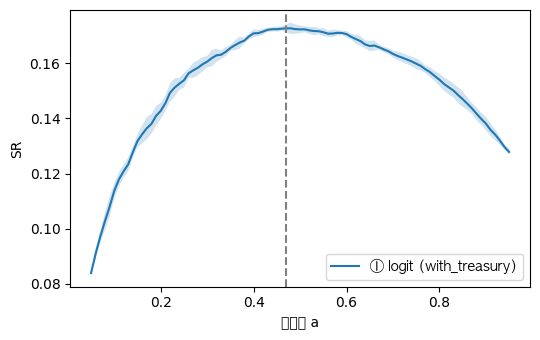

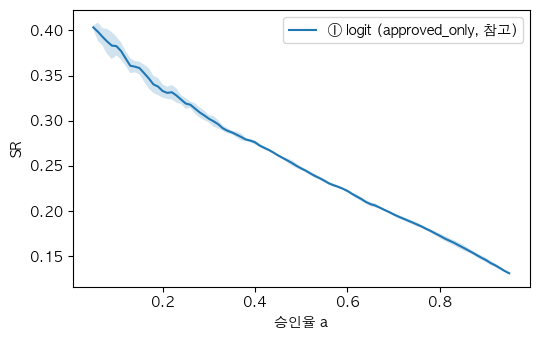

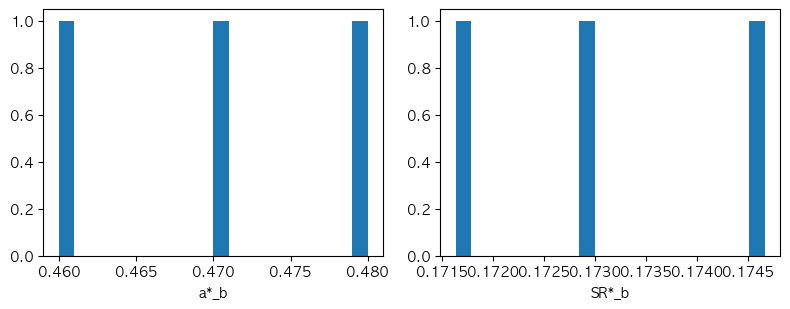

In [17]:
import matplotlib.pyplot as plt
fa, ax = plt.subplots(figsize=(5.5, 3.5))
fig_a(curves_df, summ["a_star"], ax=ax, label="① logit (%s)" % SR_MODE)
ax.legend(); fa.tight_layout(); fa.savefig(FIG / "logit_fig_a.png", dpi=300)

fr, axr = plt.subplots(figsize=(5.5, 3.5))
fig_a(curves_ref_df, None, ax=axr, label="① logit (%s, 참고)" % REF_MODE)
axr.legend(); fr.tight_layout(); fr.savefig(FIG / ("logit_fig_a_%s.png" % REF_MODE), dpi=300)

fb, axs = plt.subplots(1, 2, figsize=(8, 3.2))
fig_b(res_df, axs); fb.tight_layout(); fb.savefig(FIG / "logit_fig_b.png", dpi=300)
plt.show()

## 8-1. 결과 위치
Colab에서는 `colab_setup.py`가 `outputs/`·`report/`를 팀 Drive 공유폴더에 연결해 두었으므로 결과가 Drive에 바로 저장됩니다(내려받기 불필요).
로컬에서 돌렸다면 `outputs/logit/`과 `report/figures/logit_*.png`를 Drive 공유폴더의 같은 위치에 올리세요.

In [18]:
where = "팀 Drive 공유폴더 (colab_setup 연결)" if IN_COLAB else "로컬 → Drive 공유폴더의 같은 위치에 올릴 것"
print("결과:", OUT.resolve(), "|", FIG.resolve(), "|", where)
print("파일:", sorted(p.name for p in OUT.glob("*") if p.is_file()))

로컬 실행: 결과는 ~/Desktop/서울대/KDT/통계/팀플/lendingclub/outputs/logit 와 ~/Desktop/서울대/KDT/통계/팀플/lendingclub/report/figures


## 9. 완료 테스트 (실제 Dev)
담당 명세의 완료 테스트입니다. 2026-11-25 확인값(B = 10): with_treasury는 승인율 0.4~0.55에서 최대(SR 약 0.17~0.18)인 뒤집힌 U자,
approved_only는 승인율이 오를수록 계속 내려감(0.05에서 약 0.40, 1.00에서 0.114). 승인율 1.00에서는 두 모드의 SR이 같아야 합니다.
B_RUN = 3이면 곡선이 조금 출렁이므로 모양은 넉넉한 범위로 봅니다.

In [19]:
curve_by_mode = {SR_MODE: curves_df, REF_MODE: curves_ref_df}
wt = curve_by_mode["with_treasury"].groupby("rate")["sr"].mean()
ao = curve_by_mode["approved_only"].groupby("rate")["sr"].mean()

# (1) 같은 p̂를 두 번 넣으면 같은 곡선 (마지막 회차의 OOB p̂)
pd.testing.assert_frame_equal(sr_curve(p, excess[oob], RATES, SR_MODE), sr_curve(p, excess[oob], RATES, SR_MODE))

# (2) 승인율 1.00에서 두 모드 SR이 같음 (회차마다)
assert np.allclose(diag_df["sr_full_with_treasury"], diag_df["sr_full_approved_only"]), diag_df
sr_full = diag_df["sr_full_with_treasury"].mean()

# (3) 곡선 모양: with_treasury는 안쪽에서 최대인 뒤집힌 U자, approved_only는 내려감
shape = pd.DataFrame([
    dict(항목="with_treasury 최대 승인율", 이번=wt.idxmax(), 확인값="0.40~0.55"),
    dict(항목="with_treasury 최대 SR", 이번=round(wt.max(), 3), 확인값="0.17~0.18"),
    dict(항목="approved_only SR @0.05", 이번=round(ao.iloc[0], 3), 확인값="약 0.40"),
    dict(항목="두 모드 SR @1.00", 이번=round(sr_full, 3), 확인값="0.114"),
])
print(shape.to_string(index=False))
if globals().get("MOCK", False):
    print("모의 폴더(MOCK=True): 확인값은 실제 Dev 기준이라 곡선 모양 점검은 건너뜀")
else:
    assert 0.30 <= wt.idxmax() <= 0.70, "with_treasury 최대 위치가 확인값(0.4~0.55)과 많이 다름"
    assert wt.idxmax() > RATES[0] and wt.idxmax() < RATES[-1], "with_treasury가 뒤집힌 U자가 아님 (끝에서 최대)"
    assert ao.iloc[0] > ao.iloc[len(ao) // 2] > ao.iloc[-1], "approved_only가 승인율이 오를수록 내려가지 않음"

# (4) Train_b가 아닌 데이터로 전처리를 fit하면 실패해야 함 (final_prep은 Dev 전체로 fit됨)
try:
    assert_fit_on(final_prep, splits[0][0]); raise SystemExit("assert가 안 터짐")
except AssertionError:
    pass

# (5) β 부호 대조표가 나왔는지 (불일치는 실패가 아님)
assert len(sign_tbl) > 0 and (OUT / "sign_check.csv").exists()

# (6) 계약 파일 열이 명세 7과 같음
assert list(pd.read_csv(OUT / "bootstrap_results.csv").columns) == ["b", "a_star", "tau_star", "sr_max", "auc", "brier"]
assert list(pd.read_csv(OUT / "bootstrap_curves.csv").columns) == ["b", "rate", "sr", "tau"]
print("\nOK")

                    항목    이번       확인값
  with_treasury 최대 승인율 0.480 0.40~0.55
   with_treasury 최대 SR 0.173 0.17~0.18
approved_only SR @0.05 0.403    약 0.40
         두 모드 SR @1.00 0.113     0.114

OK
